### Problem 17 : Grover's Algorithm and Amplitude Amplification

Everything after Problem 9 has been **variational** - guess a circuit, train it, hope. That is the
NISQ style : practical today, but with no proven advantage anywhere.

Grover's algorithm is the other kind of quantum algorithm entirely. It has a **proven** speedup, it
is **optimal** (no quantum algorithm can do better), and it needs no training at all. And the engine
inside it - **amplitude amplification** - is the source of the quadratic speedups quoted throughout
quantum machine learning, including the QNN of Problem 7 and quantum clustering.

**The problem.** You have N items and a way to check whether a given item is the one you want. No
structure, no index, no sorting - just a checker.

- Classically you must try them one at a time : **O(N)**, or N/2 on average.
- Grover finds it in **O(√N)**.

For a million items that is 1,000 checks instead of 500,000.

**TASK :** Implement Grover's search from scratch, find the optimal number of iterations, and
discover what happens when you run it for too long.

📄 Original paper : https://arxiv.org/abs/quant-ph/9605043

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

simulator = AerSimulator()

#### The two ingredients

**1. The oracle.** A circuit that recognises the answer and flips its **phase** :

∣x⟩ → −∣x⟩ if x is the target, ∣x⟩ → ∣x⟩ otherwise.

Note what this is *not* : the oracle does not tell us the answer. It marks it invisibly - a phase
is not directly measurable. Building one is just building a reversible circuit for the check you
already have. Below we implement it with X gates that turn our target into ∣11…1⟩, a
multi-controlled Z, and then the X gates again to undo the relabelling.

**2. The diffuser.** The step that turns that invisible phase into visible probability. It performs
a **reflection about the average amplitude** : every amplitude a becomes 2ā − a. The marked state,
sitting below the average because it was negated, gets reflected up to well above it; everything
else sinks slightly.

Oracle then diffuser, repeated. Each round pumps a little more amplitude into the answer.

In [2]:
def oracle(n_qubits, marked):
    """Flip the phase of the |marked> basis state and nothing else."""
    qc = QuantumCircuit(n_qubits, name=f"oracle({marked})")

    # turn |marked> into |11...1| by X-ing the qubits that should be 0
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)

    # a multi-controlled Z: H, multi-controlled X, H  on the last qubit
    qc.h(n_qubits - 1)
    qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)
    qc.h(n_qubits - 1)

    # undo the relabelling
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)

    return qc


def diffuser(n_qubits):
    """Reflection about the mean amplitude: a -> 2*mean - a."""
    qc = QuantumCircuit(n_qubits, name="diffuser")
    qc.h(range(n_qubits))
    qc.x(range(n_qubits))
    qc.h(n_qubits - 1)
    qc.mcx(list(range(n_qubits - 1)), n_qubits - 1)
    qc.h(n_qubits - 1)
    qc.x(range(n_qubits))
    qc.h(range(n_qubits))
    return qc


n_qubits = 4
marked_state = '1011'          # the needle in our 16-item haystack

print(oracle(n_qubits, marked_state).draw())

                    
q_0: ───────■───────
            │       
q_1: ───────■───────
     ┌───┐  │  ┌───┐
q_2: ┤ X ├──■──┤ X ├
     ├───┤┌─┴─┐├───┤
q_3: ┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘


#### How many iterations ?

This is the part everyone gets wrong the first time. Grover is **not** "run it longer, get a better
answer". It is a **rotation**, and rotations come back around.

Write θ for the angle with sin θ = √(M/N), where M is the number of marked items. After k
iterations the probability of measuring a marked state is

**P(k) = sin²( (2k + 1)·θ )**

That is a sine wave. It rises to 1, and then - if you keep going - it comes **back down**. The
optimal number of iterations is

**k_opt ≈ (π/4)·√(N/M)**

which is exactly where the √N speedup comes from. Overshoot and you **un-find** your answer.

In [3]:
def grover(n_qubits, marked, n_iterations, shots=4096):
    """Full Grover search; returns the measured counts."""
    qc = QuantumCircuit(n_qubits, n_qubits)

    qc.h(range(n_qubits))                       # start in the uniform superposition

    for _ in range(n_iterations):
        qc.compose(oracle(n_qubits, marked), inplace=True)
        qc.compose(diffuser(n_qubits), inplace=True)

    qc.measure(range(n_qubits), range(n_qubits))
    return simulator.run(transpile(qc, simulator), shots=shots).result().get_counts()


N = 2 ** n_qubits
k_optimal = int(np.floor(np.pi / 4 * np.sqrt(N)))

print(f"Search space  : N = {N} items")
print(f"Classical cost: ~{N // 2} checks on average, {N} in the worst case")
print(f"Grover cost   : k_opt = floor(pi/4 * sqrt({N})) = {k_optimal} iterations")

Search space  : N = 16 items
Classical cost: ~8 checks on average, 16 in the worst case
Grover cost   : k_opt = floor(pi/4 * sqrt(16)) = 3 iterations


Probability of measuring '1011': 0.9602
(random guessing would give 0.0625)



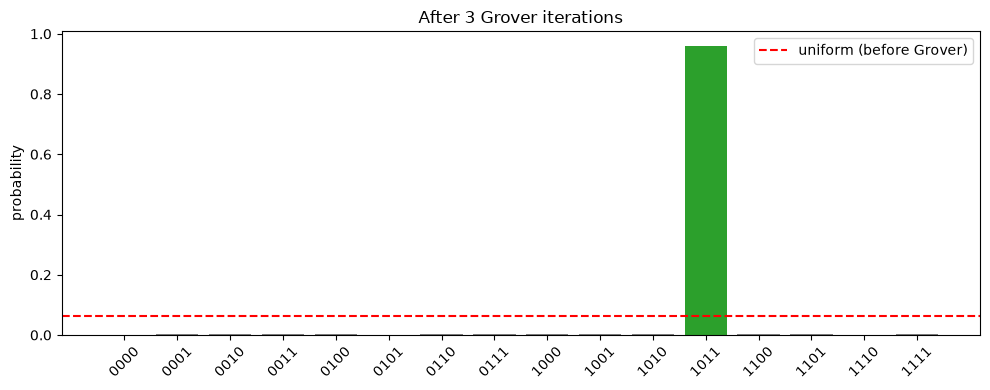

In [4]:
counts = grover(n_qubits, marked_state, k_optimal)
success = counts.get(marked_state, 0) / 4096

print(f"Probability of measuring '{marked_state}': {success:.4f}")
print(f"(random guessing would give {1 / N:.4f})")
print()

basis = [format(i, f'0{n_qubits}b') for i in range(N)]
plt.figure(figsize=(10, 4))
colors = ['tab:green' if b == marked_state else 'tab:gray' for b in basis]
plt.bar(basis, [counts.get(b, 0) / 4096 for b in basis], color=colors)
plt.axhline(1 / N, color='r', linestyle='--', label='uniform (before Grover)')
plt.xticks(rotation=45); plt.ylabel("probability")
plt.title(f"After {k_optimal} Grover iterations")
plt.legend(); plt.tight_layout(); plt.show()

#### Watch the rotation

Now the important experiment : run it for 0, 1, 2, … iterations and plot the success probability
against the theoretical sine curve.

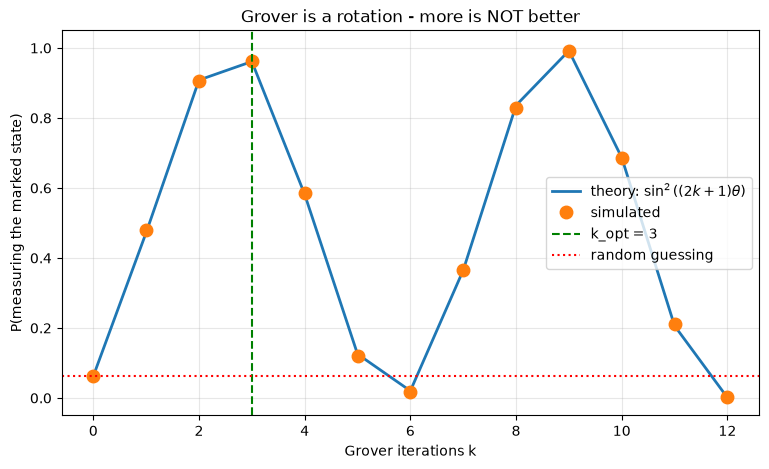

k =  0 | P(success) = 0.0623
k =  1 | P(success) = 0.4810
k =  2 | P(success) = 0.9058
k =  3 | P(success) = 0.9619  <-- optimal
k =  4 | P(success) = 0.5867
k =  5 | P(success) = 0.1194
k =  6 | P(success) = 0.0181  <-- over-rotated back to noise
k =  7 | P(success) = 0.3657
k =  8 | P(success) = 0.8279
k =  9 | P(success) = 0.9922
k = 10 | P(success) = 0.6846
k = 11 | P(success) = 0.2122
k = 12 | P(success) = 0.0015  <-- over-rotated back to noise


In [5]:
iterations = list(range(0, 13))
measured = [grover(n_qubits, marked_state, k).get(marked_state, 0) / 4096 for k in iterations]

theta = np.arcsin(np.sqrt(1 / N))
theory = [np.sin((2 * k + 1) * theta) ** 2 for k in iterations]

plt.figure(figsize=(9, 5))
plt.plot(iterations, theory, '-', linewidth=2, label=r'theory: $\sin^2((2k+1)\theta)$')
plt.plot(iterations, measured, 'o', markersize=9, label='simulated')
plt.axvline(k_optimal, color='g', linestyle='--', label=f'k_opt = {k_optimal}')
plt.axhline(1 / N, color='r', linestyle=':', label='random guessing')
plt.xlabel("Grover iterations k"); plt.ylabel("P(measuring the marked state)")
plt.title("Grover is a rotation - more is NOT better")
plt.legend(); plt.grid(alpha=0.3); plt.ylim(-0.05, 1.05); plt.show()

for k, m in zip(iterations, measured):
    tag = "  <-- optimal" if k == k_optimal else ("  <-- over-rotated back to noise" if m < 0.05 and k > 0 else "")
    print(f"k = {k:2d} | P(success) = {m:.4f}{tag}")

There it is. The success probability peaks near k = 3, then **falls all the way back down** to
roughly the random-guessing level around k = 6, and starts climbing again. The simulated points sit
right on the theoretical curve.

The practical consequence is sharp : **you must know N and M in advance to know when to stop.** If
you do not know how many solutions there are, you use a variant called *quantum counting* (built on
the phase estimation from the Qiskit lectures in `materials/`), or you use the exponential-search
trick of trying k = 1, 2, 4, 8, … until you get a hit.

#### The √N scaling

The whole point is how the cost grows. Let us tabulate it.

In [6]:
print(f"{'qubits':>7} {'N':>8} {'classical (N/2)':>17} {'Grover (k_opt)':>16} {'speedup':>9}")
for n in range(2, 21):
    N_n = 2 ** n
    k_n = int(np.floor(np.pi / 4 * np.sqrt(N_n)))
    print(f"{n:>7} {N_n:>8} {N_n // 2:>17} {k_n:>16} {(N_n / 2) / max(k_n, 1):>8.1f}x")

 qubits        N   classical (N/2)   Grover (k_opt)   speedup
      2        4                 2                1      2.0x
      3        8                 4                2      2.0x
      4       16                 8                3      2.7x
      5       32                16                4      4.0x
      6       64                32                6      5.3x
      7      128                64                8      8.0x
      8      256               128               12     10.7x
      9      512               256               17     15.1x
     10     1024               512               25     20.5x
     11     2048              1024               35     29.3x
     12     4096              2048               50     41.0x
     13     8192              4096               71     57.7x
     14    16384              8192              100     81.9x
     15    32768             16384              142    115.4x
     16    65536             32768              201    163.0x
     17 

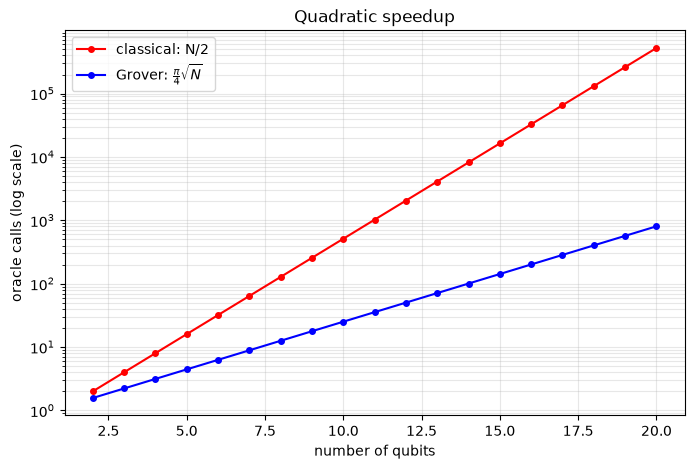

In [7]:
ns = np.arange(2, 21)
Ns = 2.0 ** ns

plt.figure(figsize=(8, 5))
plt.semilogy(ns, Ns / 2, 'r-o', markersize=4, label='classical: N/2')
plt.semilogy(ns, np.pi / 4 * np.sqrt(Ns), 'b-o', markersize=4, label=r'Grover: $\frac{\pi}{4}\sqrt{N}$')
plt.xlabel("number of qubits"); plt.ylabel("oracle calls (log scale)")
plt.title("Quadratic speedup")
plt.legend(); plt.grid(alpha=0.3, which='both'); plt.show()

#### Amplitude amplification : the part that matters for Quantum AI

Grover's search is a special case of a general primitive. Given **any** procedure A that produces a
good outcome with probability p, amplitude amplification produces it with probability ≈1 using
**O(1/√p)** repetitions instead of O(1/p). Search is just A = "uniform superposition".

That single primitive is the engine behind most quoted QML speedups :

| Application | What gets amplified |
|---|---|
| Quantum minimum finding | the smallest element - the core of quantum k-means and quantum k-NN (Problem 7) |
| Quantum counting | estimating *how many* solutions exist, via phase estimation |
| Quantum walk search | searching structured graphs |
| Speeding up sampling | any rejection-sampling style routine |

#### The catch, stated honestly

A quadratic speedup is real but modest, and it comes with heavy conditions :

1. **The oracle must be efficient.** If checking an item is expensive, √N cheap-looking iterations
   are not cheap at all. "Search a database" is misleading - you cannot Grover-search data sitting
   on a classical disk without first loading it into a quantum state, which typically costs O(N)
   and eats the entire speedup. This is the **data loading problem**, and it haunts all of QML.
2. **The circuits are deep and unforgiving.** Every iteration is a full oracle plus diffuser, all
   coherent. Go back to Problem 14 : at 3% two-qubit error you cannot survive 1,000 iterations.
   Grover essentially **requires error-corrected hardware**.
3. **Quadratic, not exponential.** Classical hardware is fast and cheap. A √N advantage has to
   overcome an enormous constant-factor handicap before it pays.

#### Key Takeaways :
- Grover finds a marked item in **O(√N)** oracle calls, and this is provably optimal.
- The oracle marks with a **phase**; the diffuser reflects about the mean to turn phase into probability.
- It is a **rotation** - stop at k ≈ (π/4)√(N/M) or you rotate the answer away.
- **Amplitude amplification** is the reusable primitive behind most QML speedup claims.
- The speedup is real, provable, and still needs fault-tolerant hardware plus an efficient oracle.

#### TASK :
1. Mark **two** states instead of one (compose two oracles). The optimal iteration count becomes
   (π/4)·√(N/2) - verify that the peak really does move earlier.
2. Scale up to 6 qubits (N = 64). Plot the success curve and check the peak lands at k = 6.
3. Use `Statevector.from_instruction` to print the amplitudes after each iteration, without
   measuring. Watch the marked amplitude grow while the others shrink - this makes the "reflection
   about the mean" picture concrete.
4. Add the noise model from Problem 14 and find the number of qubits at which noise destroys the
   advantage entirely. This is the most sobering experiment in the whole repo.